In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
%pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd

file_path = "../Afficionado Coffee Roasters.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (149116, 11)


,transaction_id,year,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2025,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2025,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2025,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2025,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2025,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [2]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    149116 non-null  int64  
 1   year              149116 non-null  int64  
 2   transaction_time  149116 non-null  object 
 3   transaction_qty   149116 non-null  int64  
 4   store_id          149116 non-null  int64  
 5   store_location    149116 non-null  str    
 6   product_id        149116 non-null  int64  
 7   unit_price        149116 non-null  float64
 8   product_category  149116 non-null  str    
 9   product_type      149116 non-null  str    
 10  product_detail    149116 non-null  str    
dtypes: float64(1), int64(5), object(1), str(4)
memory usage: 19.8+ MB


In [3]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values in Each Column:
transaction_id      0
year                0
transaction_time    0
transaction_qty     0
store_id            0
store_location      0
product_id          0
unit_price          0
product_category    0
product_type        0
product_detail      0
dtype: int64

Total Missing Values: 0


In [4]:
duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", duplicates)

Total Duplicate Rows: 0


In [5]:
df.describe()

,transaction_id,year,transaction_qty,store_id,product_id,unit_price
count,149116.000000,149116.0,149116.000000,149116.000000,149116.000000,149116.000000
mean,74737.371872,2025.0,1.438276,5.342063,47.918607,3.382219
std,43153.600016,0.0,0.542509,2.074241,17.930020,2.658723
min,1.000000,2025.0,1.000000,3.000000,1.000000,0.800000
25%,37335.750000,2025.0,1.000000,3.000000,33.000000,2.500000
50%,74727.500000,2025.0,1.000000,5.000000,47.000000,3.000000
75%,112094.250000,2025.0,2.000000,8.000000,60.000000,3.750000
max,149456.000000,2025.0,8.000000,8.000000,87.000000,45.000000


In [6]:
print("First 10 Transaction Times:")
print(df["transaction_time"].head(10))

print("\nData Type:")
print(df["transaction_time"].dtype)

First 10 Transaction Times:
0    07:06:11
1    07:08:56
2    07:14:04
3    07:20:24
4    07:22:41
5    07:22:41
6    07:25:49
7    07:33:34
8    07:39:13
9    07:39:34
Name: transaction_time, dtype: object

Data Type:
object


In [7]:
df["transaction_time"] = pd.to_datetime(
    df["transaction_time"],
    format="%H:%M:%S"
).dt.time

print("Time conversion successful!")
print(df["transaction_time"].head())

print("\nNew Data Type:")
print(df["transaction_time"].dtype)

Time conversion successful!
0    07:06:11
1    07:08:56
2    07:14:04
3    07:20:24
4    07:22:41
Name: transaction_time, dtype: object

New Data Type:
object


In [8]:
df["transaction_hour"] = pd.to_datetime(
    df["transaction_time"].astype(str),
    format="%H:%M:%S"
).dt.hour

print("Transaction hours extracted successfully!")
print(df[["transaction_time", "transaction_hour"]].head(10))

Transaction hours extracted successfully!
  transaction_time  transaction_hour
0         07:06:11                 7
1         07:08:56                 7
2         07:14:04                 7
3         07:20:24                 7
4         07:22:41                 7
5         07:22:41                 7
6         07:25:49                 7
7         07:33:34                 7
8         07:39:13                 7
9         07:39:34                 7


In [9]:
df["revenue"] = df["transaction_qty"] * df["unit_price"]

print("Revenue column created successfully!")

print("Total Revenue:", df["revenue"].sum())
print("Average Transaction Revenue:", df["revenue"].mean())
print("Maximum Transaction Revenue:", df["revenue"].max())

Revenue column created successfully!
Total Revenue: 698812.3300000001
Average Transaction Revenue: 4.6863671906435265
Maximum Transaction Revenue: 360.0


In [10]:
total_quantity = df["transaction_qty"].sum()

print("Total Products Sold:", total_quantity)
print("Average Quantity per Transaction:", df["transaction_qty"].mean())

Total Products Sold: 214470
Average Quantity per Transaction: 1.438276241315486


In [11]:
location_sales = df.groupby("store_location").agg(
    Total_Revenue=("revenue", "sum"),
    Total_Transactions=("transaction_id", "count"),
    Total_Quantity=("transaction_qty", "sum")
).round(2)

location_sales = location_sales.sort_values(
    by="Total_Revenue", ascending=False
)

location_sales

,Total_Revenue,Total_Transactions,Total_Quantity
store_location,,,
Hell's Kitchen,236511.17,50735,71737
Astoria,232243.91,50599,70991
Lower Manhattan,230057.25,47782,71742


In [12]:
category_sales = df.groupby("product_category").agg(
    Total_Revenue=("revenue", "sum"),
    Total_Transactions=("transaction_id", "count"),
    Total_Quantity=("transaction_qty", "sum")
).round(2)

category_sales = category_sales.sort_values(
    by="Total_Revenue", ascending=False
)

category_sales

,Total_Revenue,Total_Transactions,Total_Quantity
product_category,,,
Coffee,269952.45,58416,89250
Tea,196405.95,45449,69737
Bakery,82315.64,22796,23214
Drinking Chocolate,72416.00,11468,17457
Coffee beans,40085.25,1753,1828
Branded,13607.00,747,776
Loose Tea,11213.60,1210,1210
Flavours,8408.80,6790,10511
Packaged Chocolate,4407.64,487,487


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


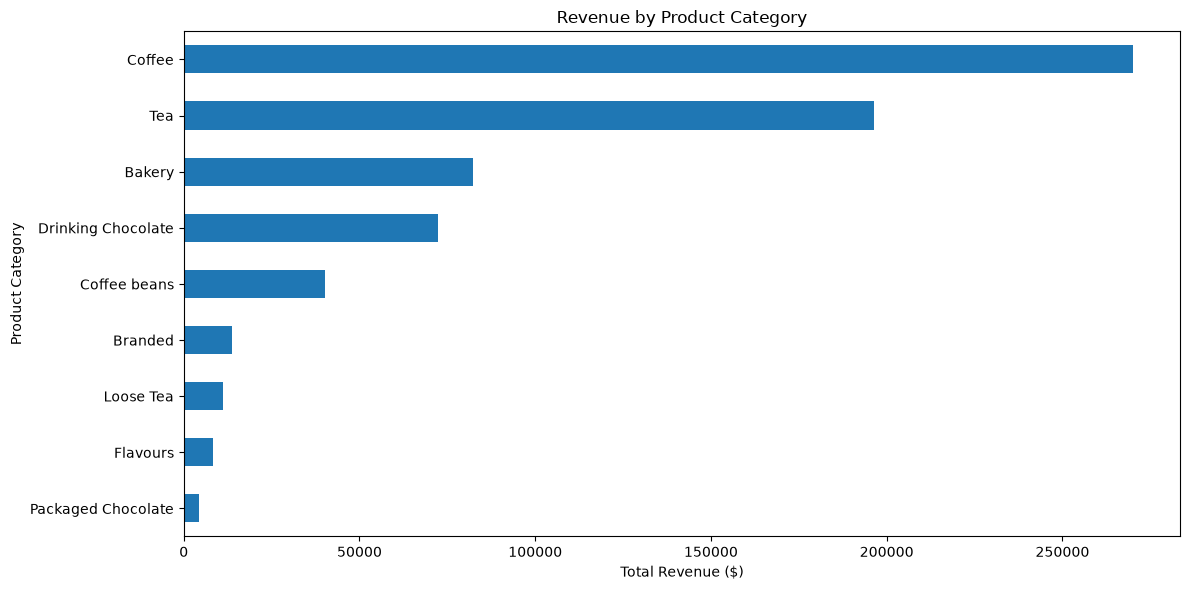

In [15]:
plt.figure(figsize=(12, 6))

category_sales["Total_Revenue"].sort_values().plot(
    kind="barh"
)

plt.title("Revenue by Product Category")
plt.xlabel("Total Revenue ($)")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig(
    "../visualization/revenue_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

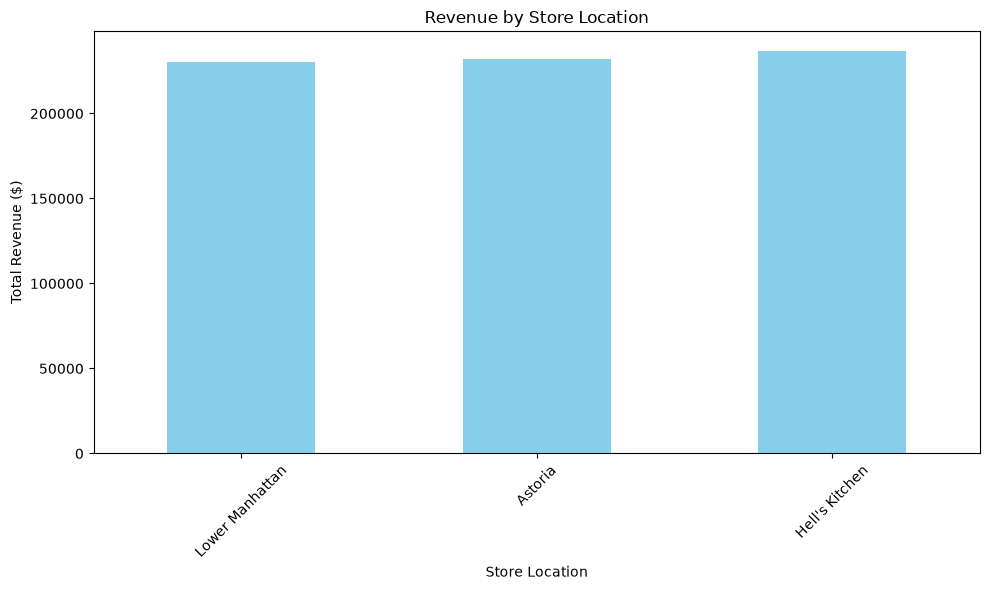

In [16]:
plt.figure(figsize=(10, 6))

location_sales["Total_Revenue"].sort_values().plot(
    kind="bar",
    color="skyblue"
)

plt.title("Revenue by Store Location")
plt.xlabel("Store Location")
plt.ylabel("Total Revenue ($)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../visualization/revenue_by_store.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


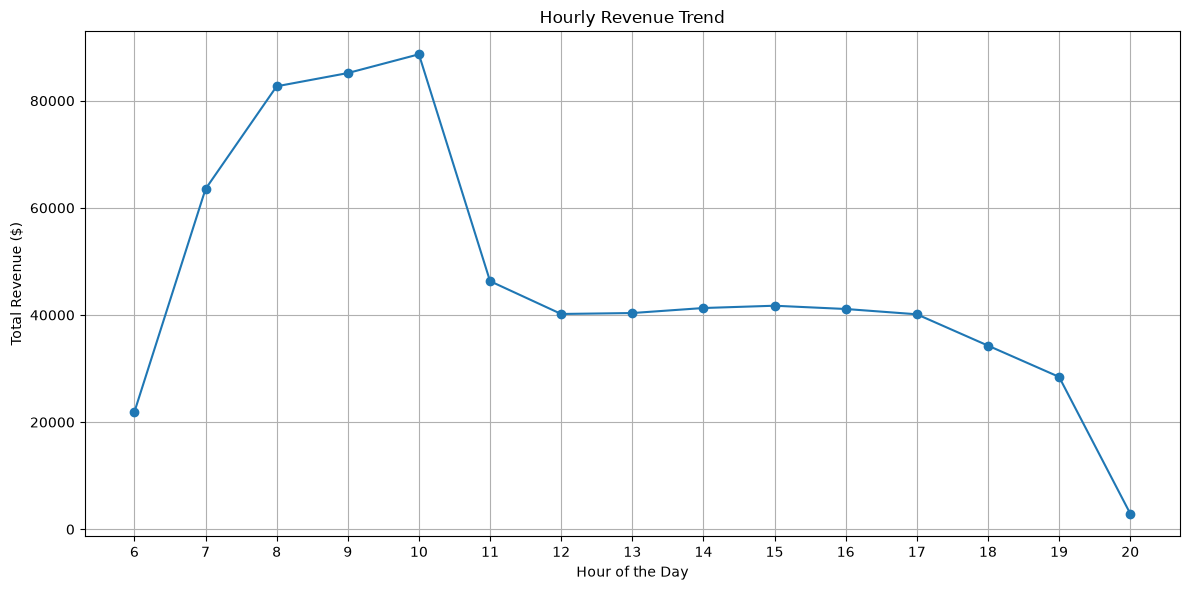

In [17]:
hourly_sales = df.groupby("transaction_hour").agg(
    Total_Revenue=("revenue", "sum"),
    Total_Transactions=("transaction_id", "count")
)

plt.figure(figsize=(12, 6))

hourly_sales["Total_Revenue"].plot(
    kind="line",
    marker="o"
)

plt.title("Hourly Revenue Trend")
plt.xlabel("Hour of the Day")
plt.ylabel("Total Revenue ($)")
plt.xticks(range(6, 21))
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "../visualization/hourly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

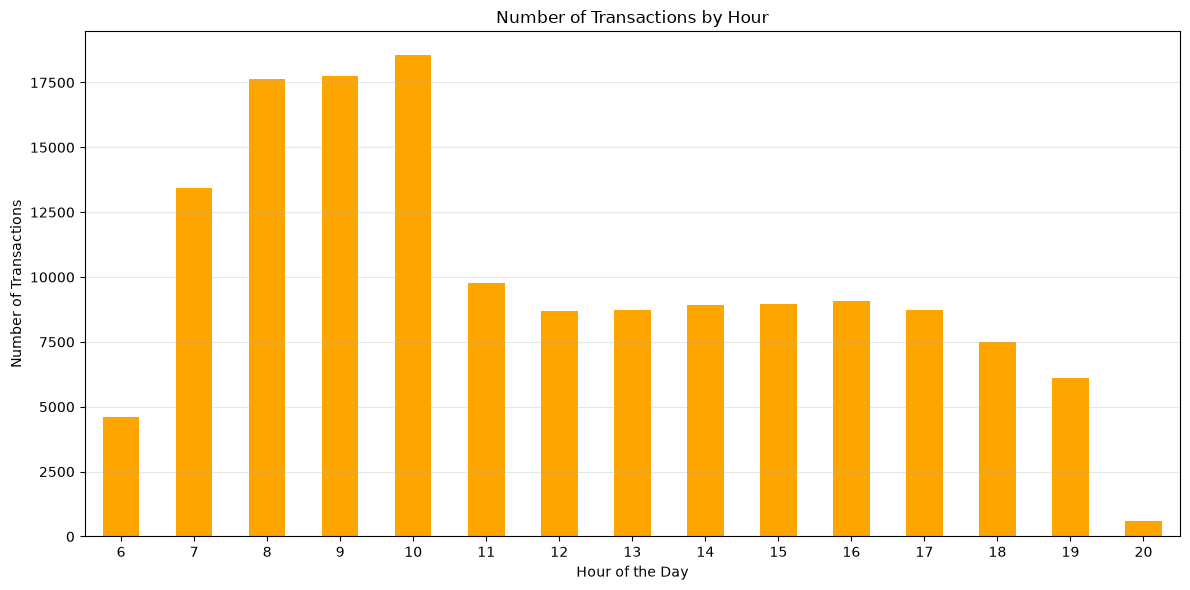

In [18]:
plt.figure(figsize=(12, 6))

hourly_sales["Total_Transactions"].plot(
    kind="bar",
    color="orange"
)

plt.title("Number of Transactions by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../visualization/transactions_by_hour.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


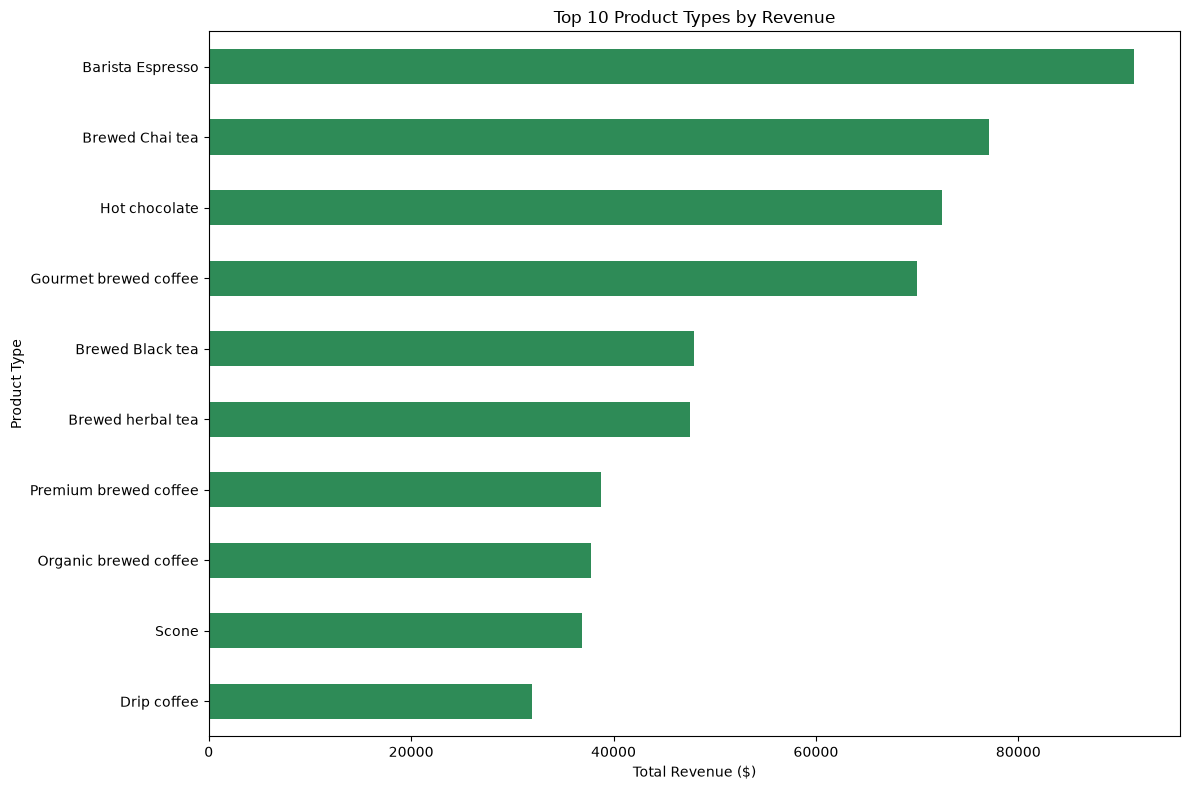

In [19]:
product_sales = df.groupby("product_type")["revenue"].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(12, 8))

product_sales.head(10).sort_values().plot(
    kind="barh",
    color="seagreen"
)

plt.title("Top 10 Product Types by Revenue")
plt.xlabel("Total Revenue ($)")
plt.ylabel("Product Type")
plt.tight_layout()

plt.savefig(
    "../visualization/top_10_product_types.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

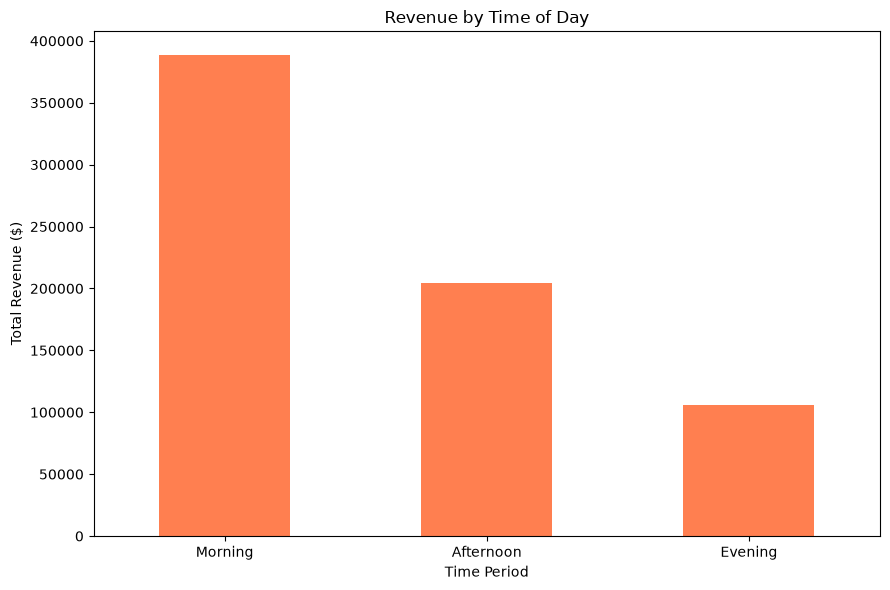

In [20]:
df["time_period"] = pd.cut(
    df["transaction_hour"],
    bins=[0, 12, 17, 24],
    labels=["Morning", "Afternoon", "Evening"],
    right=False
)

time_sales = df.groupby(
    "time_period", observed=False
)["revenue"].sum()

plt.figure(figsize=(9, 6))

time_sales.plot(
    kind="bar",
    color="coral"
)

plt.title("Revenue by Time of Day")
plt.xlabel("Time Period")
plt.ylabel("Total Revenue ($)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../visualization/revenue_by_time_period.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

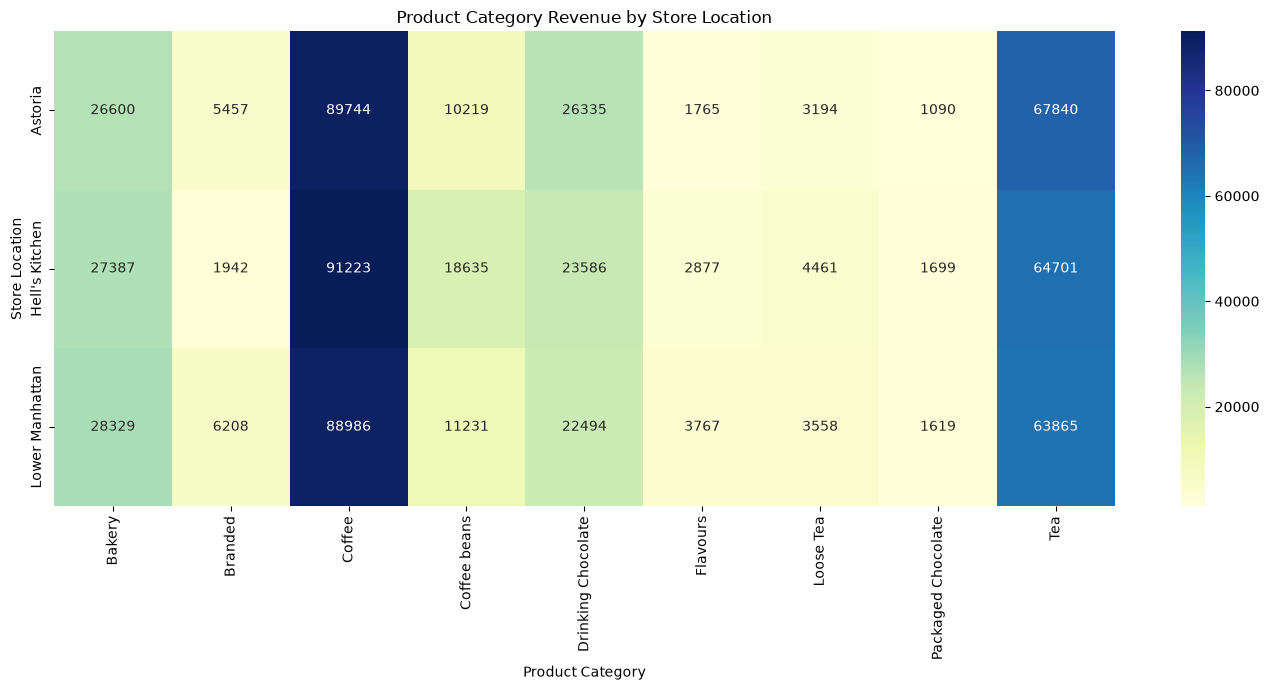

In [21]:
store_category_sales = df.pivot_table(
    index="store_location",
    columns="product_category",
    values="revenue",
    aggfunc="sum",
    fill_value=0
)

plt.figure(figsize=(14, 7))

sns.heatmap(
    store_category_sales,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Product Category Revenue by Store Location")
plt.xlabel("Product Category")
plt.ylabel("Store Location")
plt.tight_layout()

plt.savefig(
    "../visualization/store_category_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

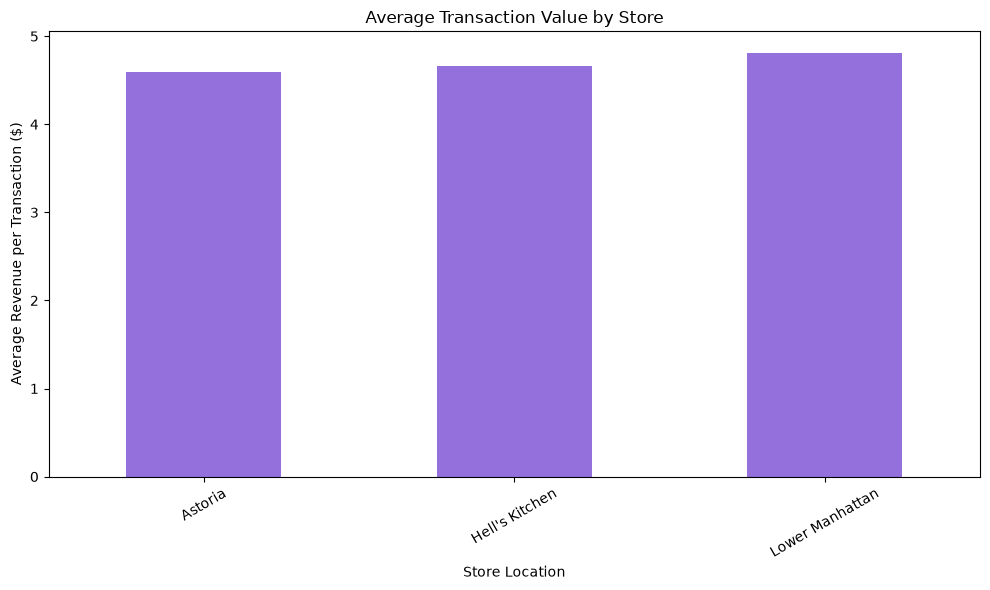

In [22]:
average_transaction = (
    location_sales["Total_Revenue"] /
    location_sales["Total_Transactions"]
)

plt.figure(figsize=(10, 6))

average_transaction.sort_values().plot(
    kind="bar",
    color="mediumpurple"
)

plt.title("Average Transaction Value by Store")
plt.xlabel("Store Location")
plt.ylabel("Average Revenue per Transaction ($)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    "../visualization/average_transaction_by_store.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
print(df.columns.tolist())

['transaction_id', 'year', 'transaction_time', 'transaction_qty', 'store_id', 'store_location', 'product_id', 'unit_price', 'product_category', 'product_type', 'product_detail', 'transaction_hour', 'revenue', 'time_period']


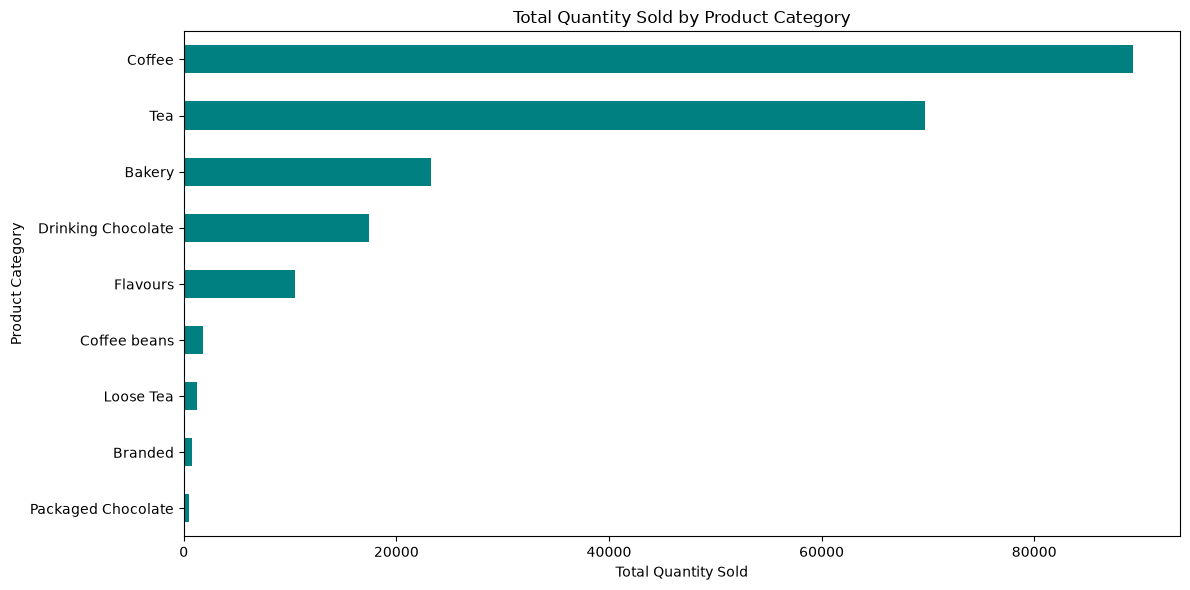

In [25]:
category_quantity = df.groupby(
    "product_category"
)["transaction_qty"].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

category_quantity.sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Total Quantity Sold by Product Category")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig(
    "../visualization/quantity_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


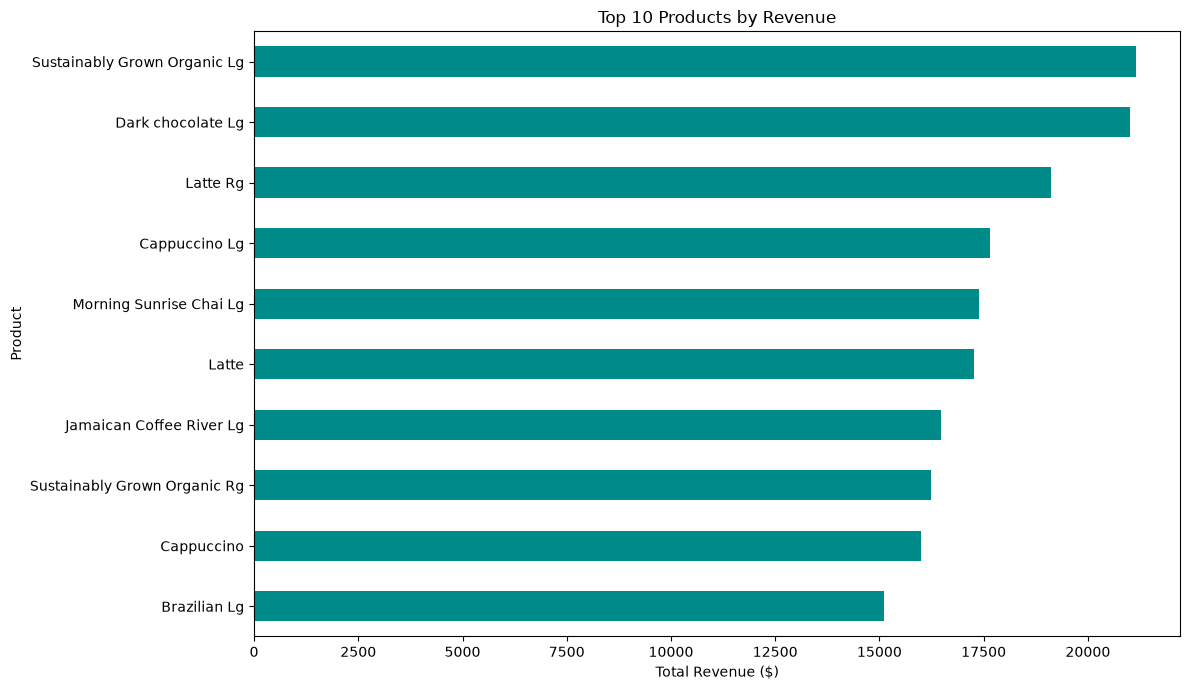

In [26]:
top_products = df.groupby(
    "product_detail"
)["revenue"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 7))

top_products.sort_values().plot(
    kind="barh",
    color="darkcyan"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue ($)")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig(
    "../visualization/top_10_products_by_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

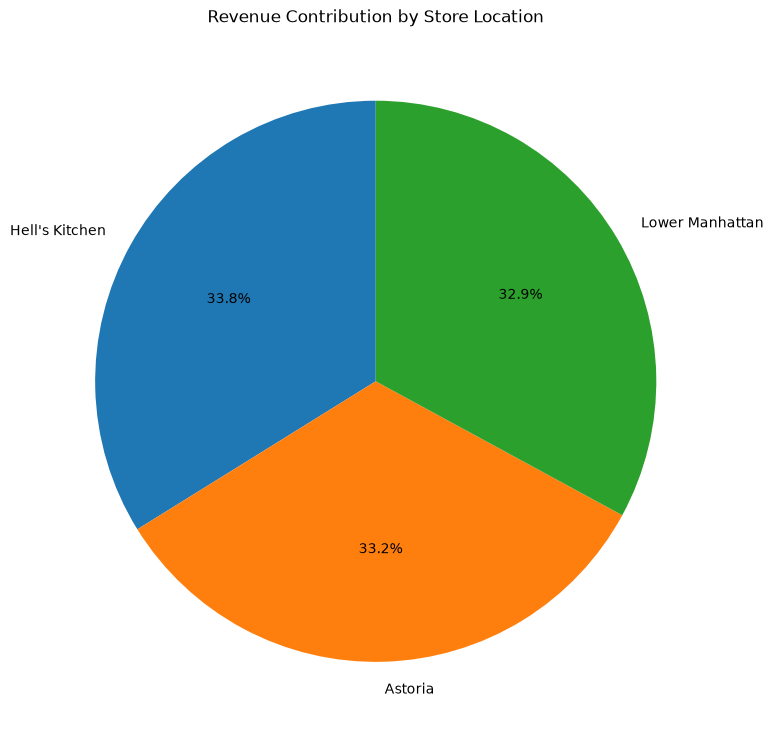

In [27]:
store_revenue_percentage = (
    location_sales["Total_Revenue"] /
    location_sales["Total_Revenue"].sum()
) * 100

plt.figure(figsize=(8, 8))

plt.pie(
    store_revenue_percentage,
    labels=store_revenue_percentage.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Contribution by Store Location")
plt.tight_layout()

plt.savefig(
    "../visualization/store_revenue_contribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

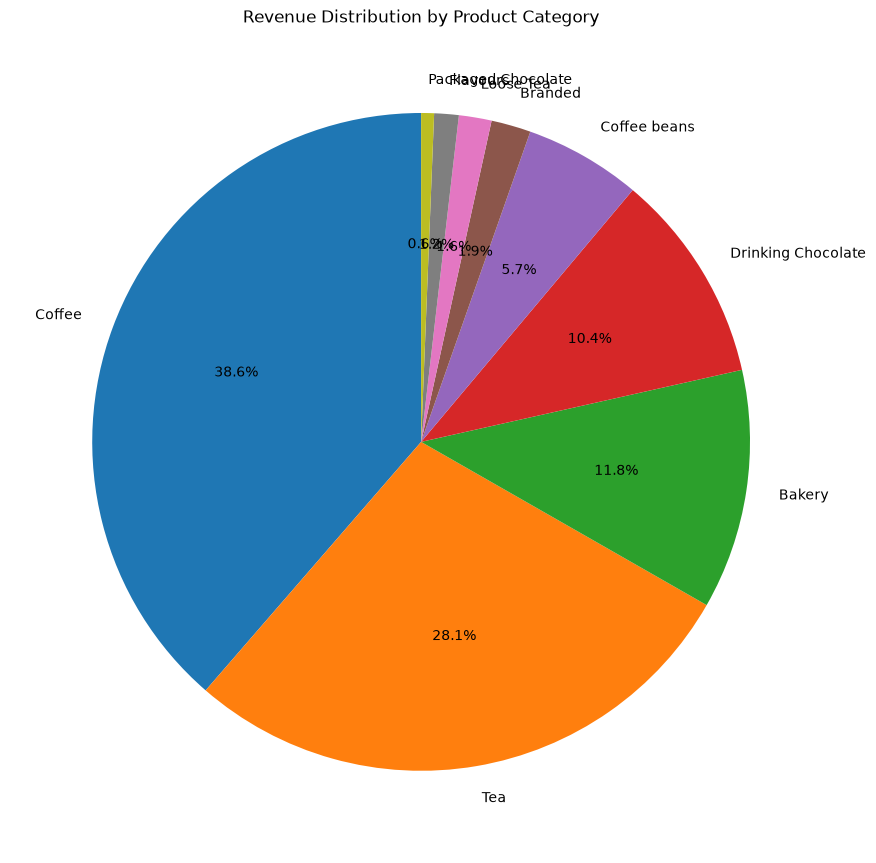

In [28]:
plt.figure(figsize=(9, 9))

plt.pie(
    category_sales["Total_Revenue"],
    labels=category_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Distribution by Product Category")
plt.tight_layout()

plt.savefig(
    "../visualization/category_revenue_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

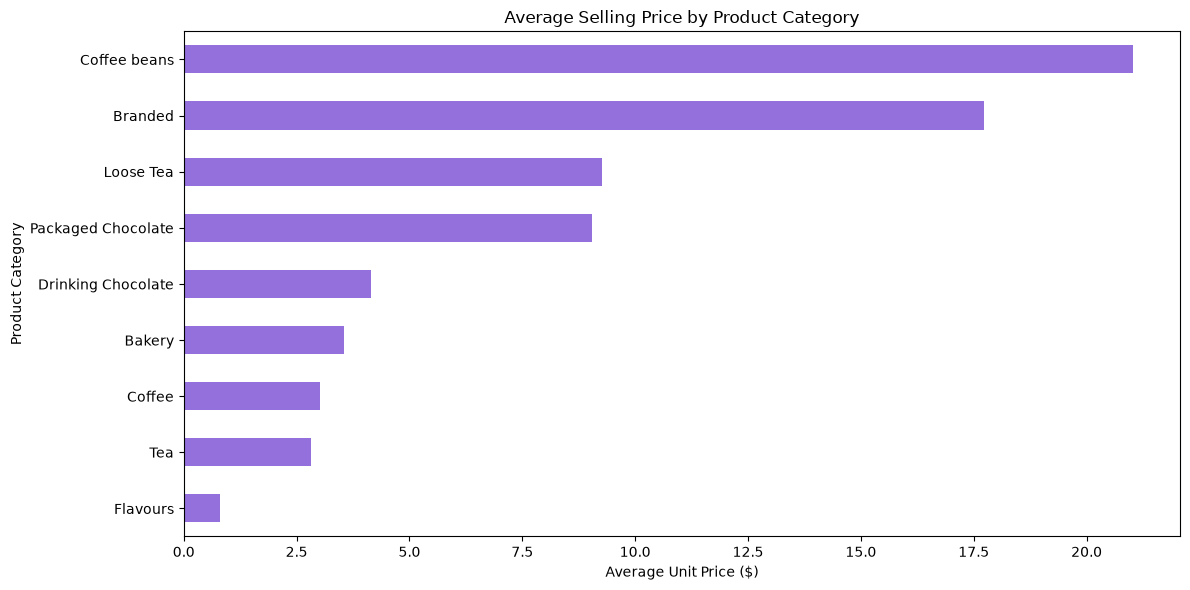

In [29]:
average_price = df.groupby(
    "product_category"
)["unit_price"].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

average_price.sort_values().plot(
    kind="barh",
    color="mediumpurple"
)

plt.title("Average Selling Price by Product Category")
plt.xlabel("Average Unit Price ($)")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig(
    "../visualization/average_price_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

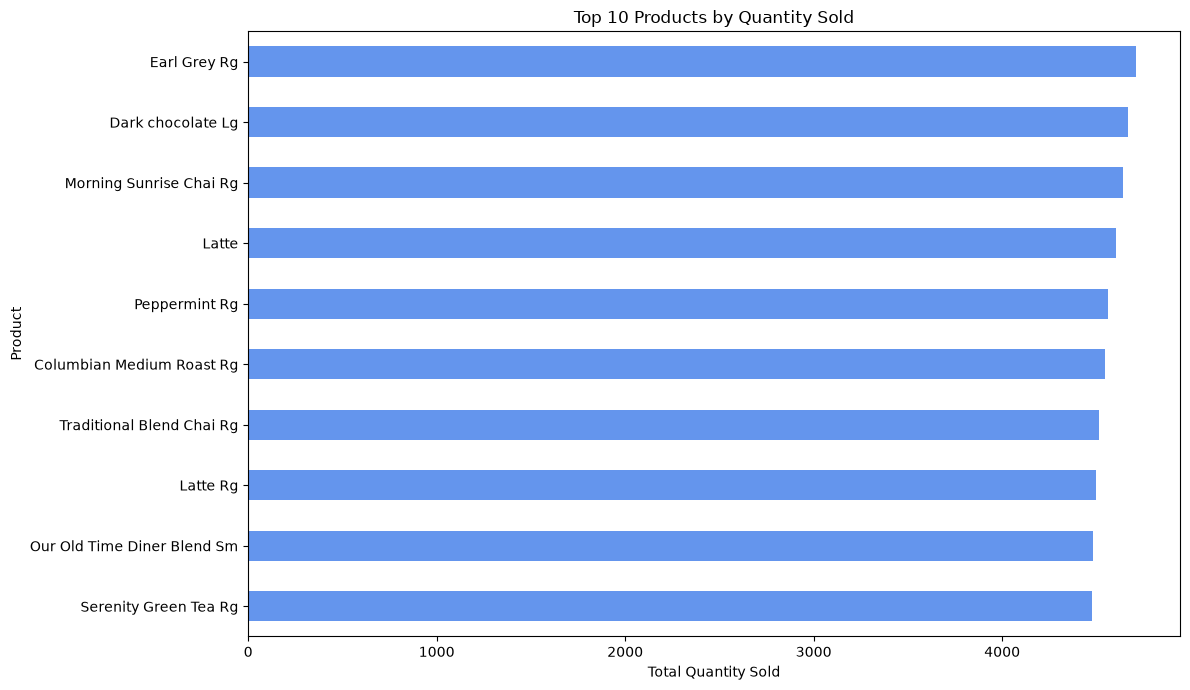

In [30]:
top_quantity_products = df.groupby(
    "product_detail"
)["transaction_qty"].sum().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(12, 7))

top_quantity_products.sort_values().plot(
    kind="barh",
    color="cornflowerblue"
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig(
    "../visualization/top_10_products_by_quantity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

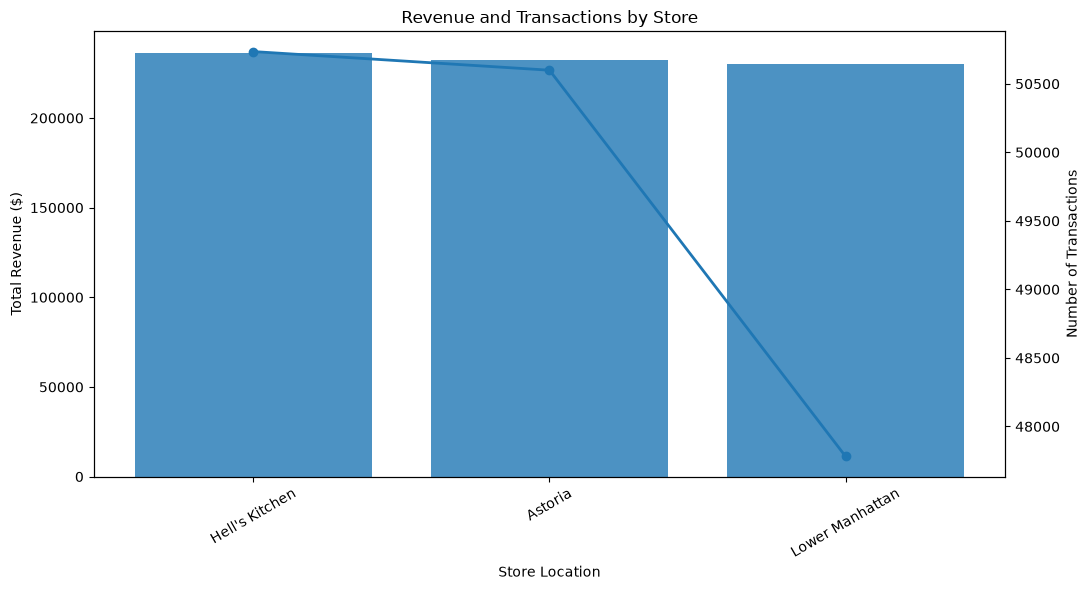

In [31]:
fig, ax1 = plt.subplots(figsize=(11, 6))

locations = location_sales.index

ax1.bar(
    locations,
    location_sales["Total_Revenue"],
    label="Revenue",
    alpha=0.8
)

ax1.set_xlabel("Store Location")
ax1.set_ylabel("Total Revenue ($)")
ax1.set_title("Revenue and Transactions by Store")
ax1.tick_params(axis="x", rotation=30)

ax2 = ax1.twinx()

ax2.plot(
    locations,
    location_sales["Total_Transactions"],
    marker="o",
    linewidth=2,
    label="Transactions"
)

ax2.set_ylabel("Number of Transactions")

fig.tight_layout()

plt.savefig(
    "../visualization/revenue_vs_transactions_by_store.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

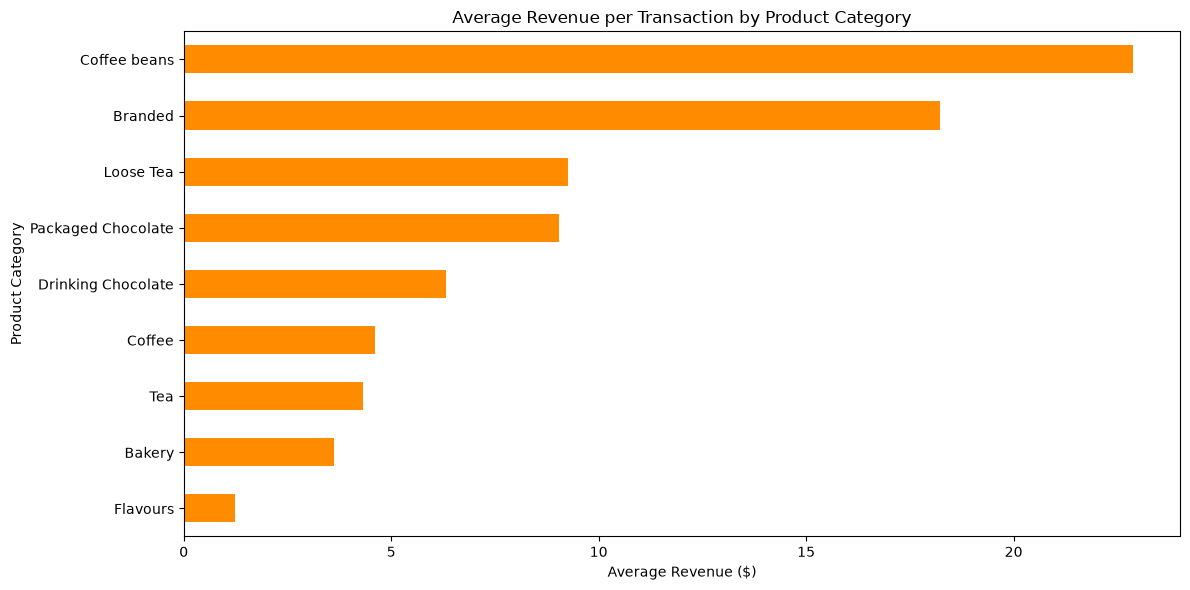

In [32]:
category_avg_transaction = df.groupby(
    "product_category"
)["revenue"].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

category_avg_transaction.sort_values().plot(
    kind="barh",
    color="darkorange"
)

plt.title("Average Revenue per Transaction by Product Category")
plt.xlabel("Average Revenue ($)")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig(
    "../visualization/average_revenue_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

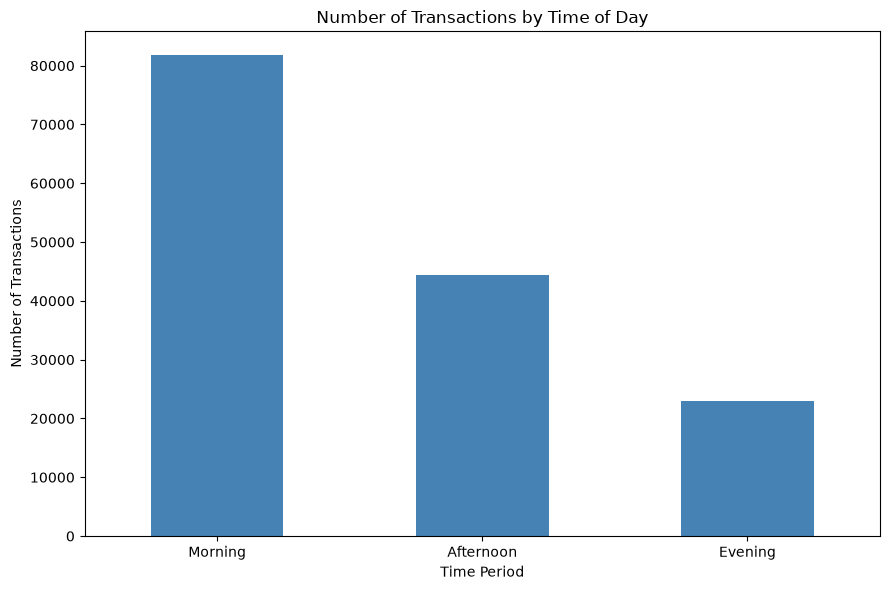

In [33]:
period_transactions = df.groupby(
    "time_period",
    observed=False
)["transaction_id"].count()

plt.figure(figsize=(9, 6))

period_transactions.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Number of Transactions by Time of Day")
plt.xlabel("Time Period")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../visualization/transactions_by_time_period.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

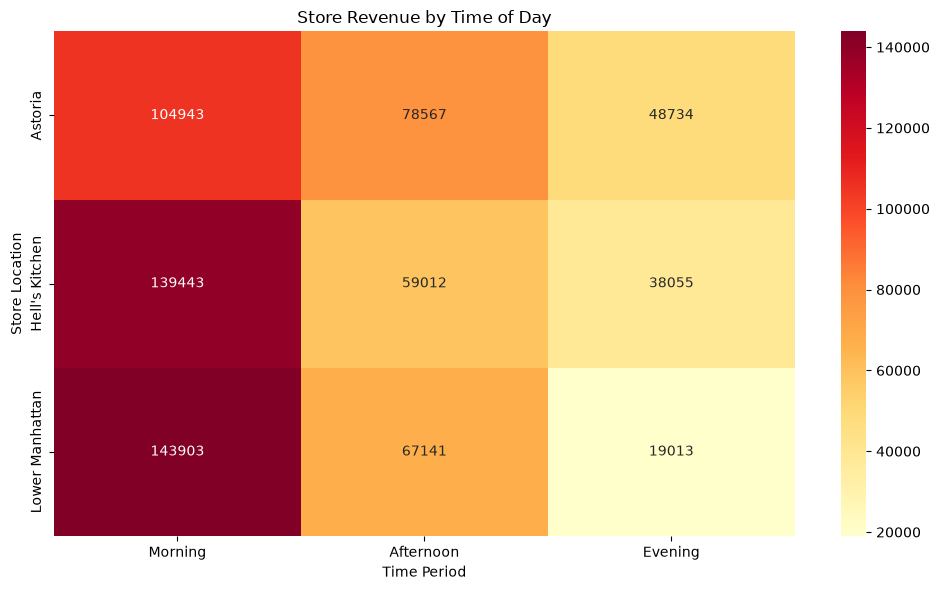

In [34]:
store_time_sales = df.pivot_table(
    index="store_location",
    columns="time_period",
    values="revenue",
    aggfunc="sum",
    fill_value=0,
    observed=False
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    store_time_sales,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd"
)

plt.title("Store Revenue by Time of Day")
plt.xlabel("Time Period")
plt.ylabel("Store Location")
plt.tight_layout()

plt.savefig(
    "../visualization/store_time_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

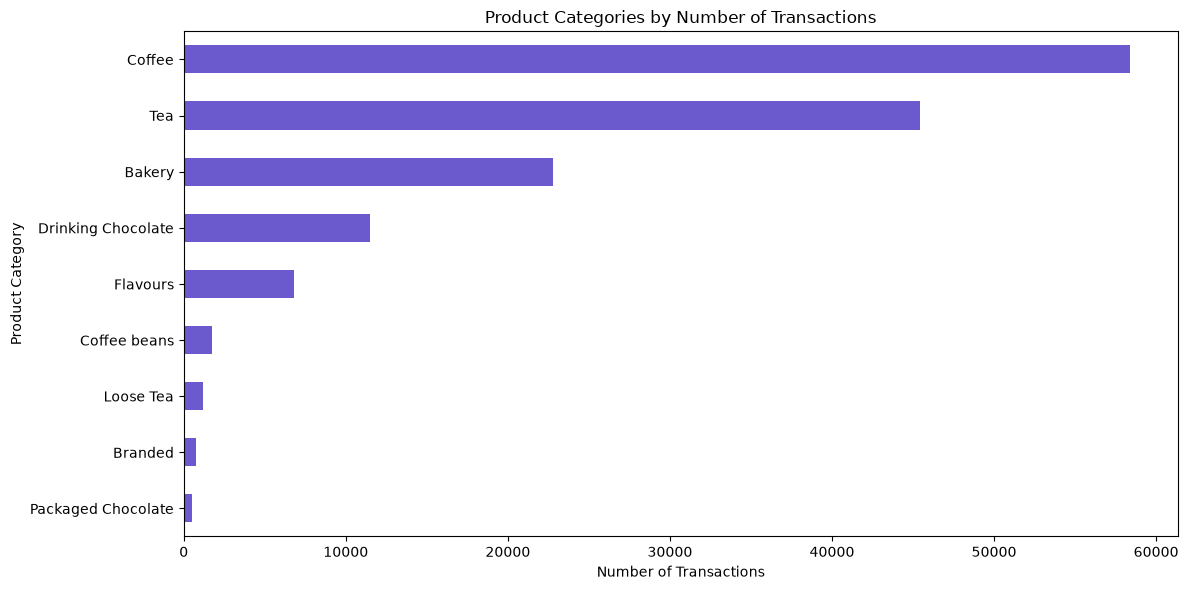

In [35]:
category_transactions = df.groupby(
    "product_category"
)["transaction_id"].count().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

category_transactions.sort_values().plot(
    kind="barh",
    color="slateblue"
)

plt.title("Product Categories by Number of Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig(
    "../visualization/category_transactions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
peak_hour = hourly_sales["Total_Revenue"].idxmax()
peak_revenue = hourly_sales["Total_Revenue"].max()

busiest_hour = hourly_sales["Total_Transactions"].idxmax()
max_transactions = hourly_sales["Total_Transactions"].max()

print("PEAK SALES HOUR ANALYSIS")
print("------------------------")
print("Highest Revenue Hour:", peak_hour, ":00")
print("Revenue at Peak Hour: $", round(peak_revenue, 2))
print("Busiest Transaction Hour:", busiest_hour, ":00")
print("Number of Transactions:", max_transactions)

PEAK SALES HOUR ANALYSIS
------------------------
Highest Revenue Hour: 10 :00
Revenue at Peak Hour: $ 88673.39
Busiest Transaction Hour: 10 :00
Number of Transactions: 18545


In [37]:
time_revenue_percentage = (
    time_sales / time_sales.sum()
) * 100

print("REVENUE CONTRIBUTION BY TIME PERIOD")
print("-----------------------------------")

print(time_revenue_percentage.round(2))

REVENUE CONTRIBUTION BY TIME PERIOD
-----------------------------------
time_period
Morning      55.56
Afternoon    29.30
Evening      15.14
Name: revenue, dtype: float64


In [38]:
total_revenue = df["revenue"].sum()
total_transactions = df["transaction_id"].nunique()
total_quantity = df["transaction_qty"].sum()
average_order_value = total_revenue / total_transactions
unique_products = df["product_detail"].nunique()
unique_categories = df["product_category"].nunique()
unique_stores = df["store_location"].nunique()

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Transactions",
        "Total Products Sold",
        "Average Transaction Value",
        "Unique Products",
        "Product Categories",
        "Store Locations"
    ],
    "Value": [
        round(total_revenue, 2),
        total_transactions,
        total_quantity,
        round(average_order_value, 2),
        unique_products,
        unique_categories,
        unique_stores
    ]
})

kpi_summary

,Metric,Value
0,Total Revenue,698812.33
1,Total Transactions,149116.00
2,Total Products Sold,214470.00
3,Average Transaction Value,4.69
4,Unique Products,80.00
5,Product Categories,9.00
6,Store Locations,3.00


In [40]:
kpi_summary.to_csv(
    "../report/project_kpi_summary.csv",
    index=False
)

print("KPI summary saved successfully!")

KPI summary saved successfully!


In [41]:
df.to_csv(
    "../report/afficionado_cleaned_dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [42]:
print("AFFICIONADO COFFEE ROASTERS")
print("SALES ANALYSIS - KEY FINDINGS")
print("=" * 40)

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Total Products Sold: {total_quantity:,}")
print(f"Average Transaction Value: ${average_order_value:.2f}")

print("\nTIME-BASED INSIGHTS")
print("-" * 40)
print(f"Peak Sales Hour: {peak_hour}:00")
print(f"Peak Hour Revenue: ${peak_revenue:,.2f}")

print("\nREVENUE BY TIME PERIOD")
print(time_revenue_percentage.round(2))

print("\nTOP REVENUE-GENERATING STORE")
print(location_sales["Total_Revenue"].idxmax())

print("\nTOP REVENUE-GENERATING CATEGORY")
print(category_sales["Total_Revenue"].idxmax())

AFFICIONADO COFFEE ROASTERS
SALES ANALYSIS - KEY FINDINGS
Total Revenue: $698,812.33
Total Transactions: 149,116
Total Products Sold: 214,470
Average Transaction Value: $4.69

TIME-BASED INSIGHTS
----------------------------------------
Peak Sales Hour: 10:00
Peak Hour Revenue: $88,673.39

REVENUE BY TIME PERIOD
time_period
Morning      55.56
Afternoon    29.30
Evening      15.14
Name: revenue, dtype: float64

TOP REVENUE-GENERATING STORE
Hell's Kitchen

TOP REVENUE-GENERATING CATEGORY
Coffee


In [43]:
findings = f"""
AFFICIONADO COFFEE ROASTERS
SALES TREND AND TIME-BASED PERFORMANCE ANALYSIS

KEY FINDINGS

1. Total Revenue: ${total_revenue:,.2f}
2. Total Transactions: {total_transactions:,}
3. Total Products Sold: {total_quantity:,}
4. Average Transaction Value: ${average_order_value:.2f}

5. Peak Sales Hour: {peak_hour}:00
6. Peak Hour Revenue: ${peak_revenue:,.2f}

7. Morning Revenue Contribution: 55.56%
8. Afternoon Revenue Contribution: 29.30%
9. Evening Revenue Contribution: 15.14%

10. Top Store: {location_sales["Total_Revenue"].idxmax()}
11. Top Product Category: {category_sales["Total_Revenue"].idxmax()}
"""

with open("../report/project_key_findings.txt", "w") as file:
    file.write(findings)

print("Project findings saved successfully!")


Project findings saved successfully!


In [45]:
%pip install tabulate


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [46]:
report = """
# SALES TREND AND TIME-BASED PERFORMANCE ANALYSIS
## Afficionado Coffee Roasters

### 1. Introduction
This project analyses the sales performance of Afficionado Coffee Roasters
using Python and data analytics techniques. It identifies sales patterns,
store performance and product category performance.

### 2. Project Objectives
- Analyse overall sales and revenue.
- Identify peak sales hours.
- Compare revenue across store locations.
- Evaluate product category performance.
- Analyse sales across different times of the day.
- Generate business insights.

### 3. Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

### 4. Dataset Overview
The dataset contains 149,116 transactions and 11 original columns.
It includes transaction details, store locations, product information,
quantities and unit prices.

### 5. Key Performance Indicators
"""

report += "\n" + kpi_summary.to_markdown(index=False)

report += f"""

### 6. Key Findings

- Total Revenue: ${total_revenue:,.2f}
- Total Transactions: {total_transactions:,}
- Total Products Sold: {total_quantity:,}
- Average Transaction Value: ${average_order_value:.2f}
- Peak Sales Hour: {peak_hour}:00
- Peak Hour Revenue: ${peak_revenue:,.2f}
- Top Revenue-Generating Store: {location_sales["Total_Revenue"].idxmax()}
- Top Revenue-Generating Category: {category_sales["Total_Revenue"].idxmax()}

### 7. Revenue Contribution by Time Period

{time_revenue_percentage.round(2).to_string()}

### 8. Conclusion

The analysis highlights the importance of morning sales, with morning
contributing 55.56% of total revenue. The peak sales hour is 10:00 AM.
Hell's Kitchen is the highest revenue-generating store, while Coffee
is the leading product category.

These findings can support better staffing, inventory planning and
business decision-making.
"""

with open("../report/Afficionado_Coffee_Project_Report.md", "w") as file:
    file.write(report)

print("Project report created successfully!")

Project report created successfully!


In [47]:
import os

print(os.path.abspath("../report"))
print(os.listdir("../report"))

/Users/vanshikapundir9012/Projects/Afficionado_Coffee_Analysis/report
['project_kpi_summary.csv', 'project_key_findings.txt', 'afficionado_cleaned_dataset.csv', 'Afficionado_Coffee_Project_Report.md']


In [48]:
%pip install markdown


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [49]:
import markdown

with open("../report/Afficionado_Coffee_Project_Report.md", "r") as file:
    report_text = file.read()

html_content = markdown.markdown(
    report_text,
    extensions=["tables"]
)

full_html = f"""
<html>
<head>
<title>Afficionado Coffee Roasters Report</title>
<style>
body {{
    font-family: Arial, sans-serif;
    max-width: 900px;
    margin: 40px auto;
    line-height: 1.6;
    padding: 20px;
}}
h1, h2, h3 {{
    color: #4b3025;
}}
table {{
    border-collapse: collapse;
    width: 100%;
}}
th, td {{
    border: 1px solid #ccc;
    padding: 8px;
    text-align: left;
}}
</style>
</head>
<body>
{html_content}
</body>
</html>
"""

with open("../report/Afficionado_Coffee_Project_Report.html", "w") as file:
    file.write(full_html)

print("HTML report created successfully!")

HTML report created successfully!


In [50]:
import os
from IPython.display import display, HTML

html_path = os.path.abspath(
    "../report/Afficionado_Coffee_Project_Report.html"
)

display(HTML(f'<a href="file://{html_path}" target="_blank">Open Project Report</a>'))